# 17 - SW4 reference cases: ShakerMaker engines against finite differences

Six cases computed once with **SW4** (4th-order finite differences, elastic) and with ShakerMaker, stored in `../data/`
so that this notebook and the smoke tests only read them:

| Case | Medium | Source |
|---|---|---|
| `loh1_p1`, `loh1_p2`, `loh1_f1` | SCEC LOH.1 (1 km at Vs 2 km/s over a half-space) | point at 2 km, point at 0.5 km, 16 x 16 = 256 subfaults (0.3-3.76 km) |
| `layered_p1`, `layered_p2`, `layered_f1` | layered 1D crust (200 m at Vs 0.75, 800 m at 1.57, 14.5 km at 3.14 km/s, half-space at 4.0) | point at 6 km, point at 0.5 km, 256 subfaults |

All sources share an oblique mechanism (strike 30, dip 60, rake 45) and a unit-area Gaussian (sigma 0.06 s in
LOH.1, 0.1 s in the layered crust). About 100 receivers per medium, all on SW4 grid nodes: a surface ring
(1, 4 and 8 km every 30 deg), three verticals down to 8 km, the epicentre and 24 nodes of a DRM box.

ShakerMaker engines (`run_shakermaker.py`): `exact` (one Green's function per pair), `nearest` (one per slot,
copied, production tolerances) and `run_inter(scheme='tensor')` (interpolated in distance, production
configuration). Nothing is computed here: the notebook runs in seconds.

In [1]:
import csv, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import butter, sosfiltfilt

data = os.path.join("..", "data")
cases = ["loh1_p1", "loh1_p2", "loh1_f1", "layered_p1", "layered_p2", "layered_f1"]
engines = ["exact", "nearest", "inter_tensor"]
tmax = {"loh1": 12.0, "layered": 15.0}
dt = 0.01
bands = {"0.1-0.5 Hz": (0.1, 0.5), "0.5-1 Hz": (0.5, 1.0), "1-2 Hz": (1.0, 2.0)}
receivers = {m: pd.read_csv(os.path.join(data, f"receivers_{m}.csv")) for m in ("loh1", "layered")}


def load_sw4(case):
    """SW4 velocity (north, east, down) integrated in time -> (z, e, n) on [0, tmax) at dt."""
    d = np.load(os.path.join(data, "sw4", f"{case}.npz"))
    t, v = d["t"], d["vel"].astype(float)
    u = np.concatenate([np.zeros(v.shape[:2] + (1,)), np.cumsum(0.5 * (v[..., 1:] + v[..., :-1]) * np.diff(t), axis=-1)], axis=-1)
    tc = np.arange(0.0, tmax[case.split("_")[0]], dt)
    zen = u[:, [2, 1, 0]]
    return list(d["names"]), np.array([[np.interp(tc, t, x) for x in r] for r in zen])


def load_sm(case, engine):
    p = os.path.join(data, "sm", f"{case}_{engine}.npz")
    if not os.path.exists(p):
        return None
    d = np.load(p)
    tc = np.arange(0.0, tmax[case.split("_")[0]], dt)
    return np.array([[np.interp(tc, d["t"], x, left=0.0, right=x[-1]) for x in r] for r in d["zen"].astype(float)])


def band(x, f1, f2):
    return sosfiltfilt(butter(4, [f1, f2], btype="band", fs=1 / dt, output="sos"), x, axis=-1)


sw4 = {c: load_sw4(c) for c in cases}
sm = {(c, e): load_sm(c, e) for c in cases for e in engines}
print({c: sw4[c][1].shape for c in cases})

{'loh1_p1': (98, 3, 1200), 'loh1_p2': (98, 3, 1200), 'loh1_f1': (98, 3, 1200), 'layered_p1': (101, 3, 1500), 'layered_p2': (101, 3, 1500), 'layered_f1': (101, 3, 1500)}


## Model and receivers

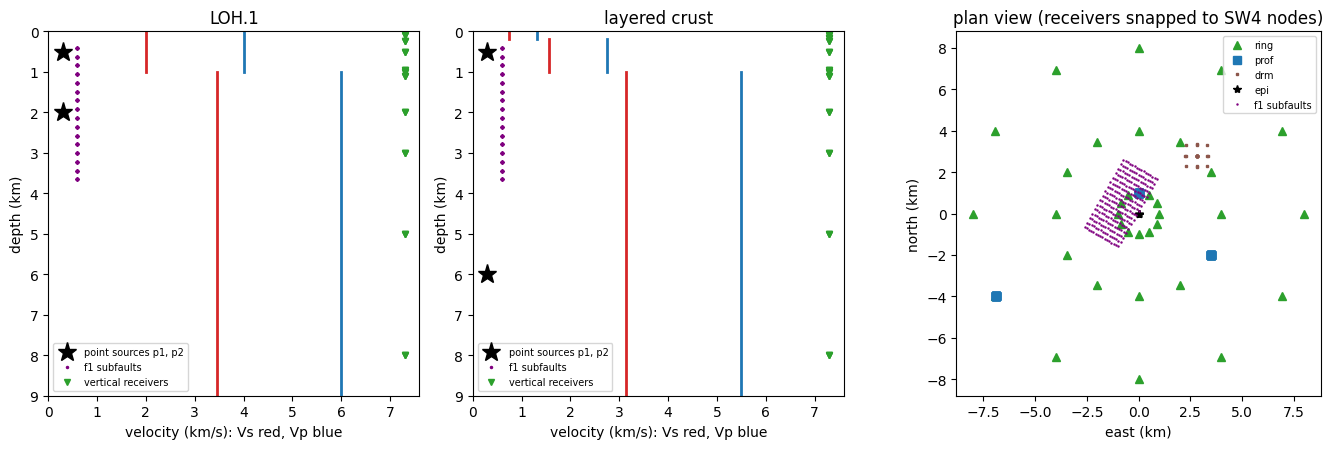

In [2]:
layers = {"loh1": [(1.0, 4.0, 2.0), (0.0, 6.0, 3.464)],
          "layered": [(0.2, 1.32, 0.75), (0.8, 2.75, 1.57), (14.5, 5.50, 3.14), (0.0, 7.00, 4.00)]}
zsrc = {"loh1": (2.0, 0.5), "layered": (6.0, 0.5)}
fault = {m: pd.read_csv(os.path.join(data, f"fault_{m}.csv")) for m in ("loh1", "layered")}
fig, ax = plt.subplots(1, 3, figsize=(14, 4.6), gridspec_kw={"width_ratios": [1, 1, 1.3]})
for a, m, title in ((ax[0], "loh1", "LOH.1"), (ax[1], "layered", "layered crust")):
    top = 0.0
    for d, vp, vs in layers[m]:
        bot = top + d if d > 0 else 10.0
        a.plot([vs, vs], [top, bot], "tab:red", lw=2)
        a.plot([vp, vp], [top, bot], "tab:blue", lw=2)
        top = bot
    a.plot([0.3] * 2, zsrc[m], "*", ms=14, color="k", label="point sources p1, p2")
    a.plot(np.full(len(fault[m]), 0.6), fault[m].depth_km, ".", color="purple", ms=3, label="f1 subfaults")
    r = receivers[m]
    a.plot(np.full((r.group == "prof").sum(), 7.3), r[r.group == "prof"].depth_km, "v", color="tab:green", ms=4, label="vertical receivers")
    a.set_ylim(9, 0); a.set_xlim(0, 7.6); a.set_xlabel("velocity (km/s): Vs red, Vp blue"); a.set_ylabel("depth (km)")
    a.set_title(title); a.legend(fontsize=7, loc="lower left")
r = receivers["layered"]
for g, mk, col in (("ring", "^", "tab:green"), ("prof", "s", "tab:blue"), ("drm", "s", "tab:brown"), ("epi", "*", "k")):
    s = r[r.group == g]
    ax[2].plot(s.east_km, s.north_km, mk, color=col, ms=6 if g != "drm" else 2, label=g)
ax[2].plot(fault["layered"].east_km, fault["layered"].north_km, ".", color="purple", ms=1.5, label="f1 subfaults")
ax[2].set_aspect("equal"); ax[2].set_xlabel("east (km)"); ax[2].set_ylabel("north (km)"); ax[2].legend(fontsize=7)
ax[2].set_title("plan view (receivers snapped to SW4 nodes)")
fig.tight_layout(); fig.savefig("model_and_receivers.png", dpi=130)

## Convention and amplitude

SW4 records velocity (x north, y east, z down). With `Gaussian(derivative=False)` the ShakerMaker output is the time
integral of the SW4 velocity for `type=Gaussian` (example 15), so the SW4 velocity is integrated (cumulative
trapezoid; no baseline correction). **Amplitudes are absolute**: one ShakerMaker moment unit is 1e15 N m in SW4 and
no factor is fitted.

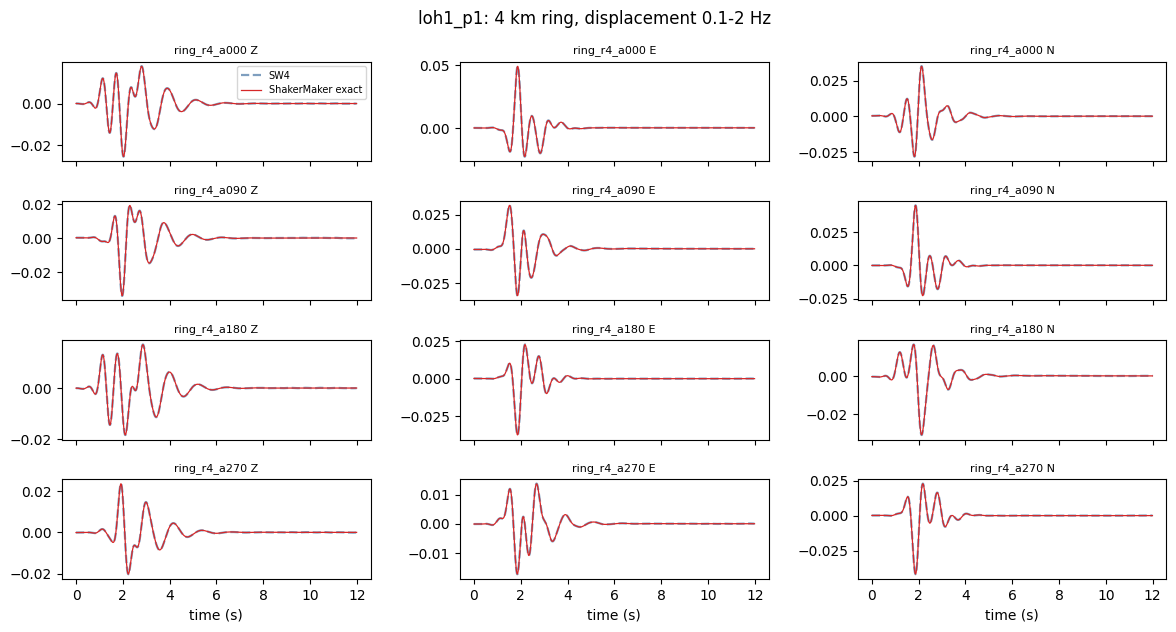

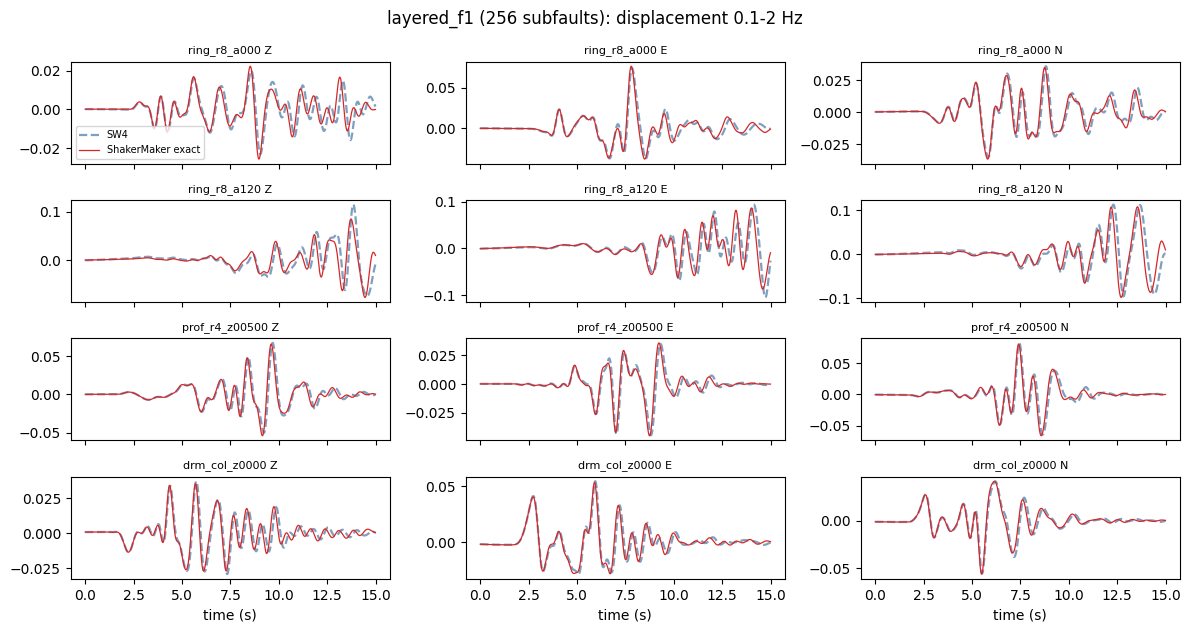

In [3]:
def traces_figure(case, names, title, fname, f1=0.1, f2=2.0):
    n4, u4 = sw4[case]
    u = sm[(case, "exact")]
    tc = np.arange(0.0, tmax[case.split("_")[0]], dt)
    fig, ax = plt.subplots(len(names), 3, figsize=(12, 1.6 * len(names)), sharex=True)
    for i, nm in enumerate(names):
        k = n4.index(nm)
        a, b = band(u4[k], f1, f2), band(u[k], f1, f2)
        for j, comp in enumerate("ZEN"):
            ax[i, j].plot(tc, a[j], "--", color="#7f9fbf", lw=1.6, label="SW4")
            ax[i, j].plot(tc, b[j], color="tab:red", lw=0.9, label="ShakerMaker exact")
            ax[i, j].set_title(f"{nm} {comp}", fontsize=8)
    ax[0, 0].legend(fontsize=7); [a.set_xlabel("time (s)") for a in ax[-1]]
    fig.suptitle(title); fig.tight_layout(); fig.savefig(fname, dpi=130)


traces_figure("loh1_p1", [f"ring_r4_a{a:03d}" for a in (0, 90, 180, 270)], "loh1_p1: 4 km ring, displacement 0.1-2 Hz", "traces_loh1_p1_ring.png")
traces_figure("layered_f1", ["ring_r8_a000", "ring_r8_a120", "prof_r4_z00500", "drm_col_z0000"], "layered_f1 (256 subfaults): displacement 0.1-2 Hz", "traces_layered_f1.png")

## Agreement with SW4 per band

Zero-lag correlation and peak ratio ShakerMaker / SW4, per receiver and component, medians over the receivers.
Components without signal in SW4 (energy below 5 % of the largest component of the receiver, nodal planes) are
left out, and so are the epicentral receivers within 100 m of a point source (one SW4 cell: SW4 smooths the source
there).

In [4]:
def metrics(case, engine, f1, f2):
    n4, u4 = sw4[case]
    u = sm[(case, engine)]
    if u is None:
        return None
    a, b = band(u4, f1, f2), band(u, f1, f2)
    ccs, pks, names_used = [], [], []
    for i, nm in enumerate(n4):
        if nm.startswith("epi_z0") and nm != "epi_z00000":
            continue
        e = np.linalg.norm(a[i], axis=-1)
        for k in range(3):
            if e[k] < 0.05 * e.max():
                continue
            ccs.append(np.corrcoef(a[i, k], b[i, k])[0, 1]); pks.append(np.abs(b[i, k]).max() / np.abs(a[i, k]).max()); names_used.append(nm)
    return np.array(ccs), np.array(pks), names_used


rows = []
for case in cases:
    for engine in engines:
        for bn, (f1, f2) in bands.items():
            m = metrics(case, engine, f1, f2)
            if m is not None:
                rows.append(dict(case=case, engine=engine, band=bn, cc_median=np.median(m[0]), cc_p05=np.percentile(m[0], 5),
                                 peak_median=np.median(m[1]), n=len(m[0])))
table = pd.DataFrame(rows)
table.to_csv("agreement_with_sw4.csv", index=False)
table.pivot_table(index=["case", "engine"], columns="band", values=["cc_median", "cc_p05", "peak_median"]).round(3)

cc_median                     cc_p05                  \
band                    0.1-0.5 Hz 0.5-1 Hz 1-2 Hz 0.1-0.5 Hz 0.5-1 Hz 1-2 Hz   
case       engine                                                               
layered_f1 exact             0.999    0.979  0.925      0.991    0.885  0.575   
           nearest           0.999    0.980  0.922      0.991    0.881  0.553   
layered_p1 exact             1.000    0.997  0.997      0.999    0.984  0.976   
           inter_tensor      1.000    0.997  0.997      0.999    0.984  0.976   
           nearest           1.000    0.997  0.997      0.999    0.984  0.976   
layered_p2 exact             0.997    0.978  0.907      0.982    0.694  0.402   
           inter_tensor      0.997    0.978  0.907      0.980    0.702  0.402   
           nearest           0.997    0.973  0.894      0.984    0.697  0.408   
loh1_f1    exact             1.000    1.000  1.000      1.000    0.998  0.999   
           inter_tensor      1.000    1.000  1.000      1.000    0.998  0.999   
           nearest           1.000    1.000  1.000      0.999    0.998  0.997   
loh1_p1    exact             1.000    1.000  1.000      1.000    1.000  1.000   
           inter_tensor      1.000    1.000  1.000      0.877    0.982  0.994   
           nearest           1.000    1.000  1.000      0.998    0.999  0.999   
loh1_p2    exact             1.000    1.000  1.000      0.999    1.000  1.000   
           inter_tensor      1.000    1.000  1.000      0.437    0.988  0.998   
           nearest           1.000    1.000  1.000      0.672    0.958  0.982   

                        peak_median                  
band                     0.1-0.5 Hz 0.5-1 Hz 1-2 Hz  
case       engine                                    
layered_f1 exact              0.993    0.992  0.984  
           nearest            0.993    0.993  0.987  
layered_p1 exact              0.993    0.987  0.996  
           inter_tensor       0.991    0.986  0.996  
           nearest            0.994    0.987  0.996  
layered_p2 exact              0.965    0.971  0.978  
           inter_tensor       0.964    0.971  0.978  
           nearest            0.967    0.972  0.981  
loh1_f1    exact              1.002    1.008  0.989  
           inter_tensor       1.002    1.009  0.989  
           nearest            1.002    1.010  0.991  
loh1_p1    exact              0.999    0.996  0.996  
           inter_tensor       0.998    0.996  0.996  
           nearest            0.999    0.996  0.996  
loh1_p2    exact              0.999    0.996  0.994  
           inter_tensor       0.999    0.995  0.994  
           nearest            0.998    0.994  0.994

## Engines against the exact reference

Low-pass 2 Hz (the band of the comparison; `inter_tensor` stops the core at `freq_cut` = 2.5 Hz, so above it the
engines differ by construction). Two errors: the traces (max |difference| / peak, median over receivers) and the
difference between the two layers of the DRM box faces (what a DRM layer turns into effective forces).

In [5]:
lp = butter(4, 2.0, btype="low", fs=1 / dt, output="sos")
pairs = [(f"drm_face_{s}_out", f"drm_face_{s}_in") for s in "nsew"] + [("drm_col_z0550", "drm_col_z0500")]
rows = []
for case in cases:
    n4 = sw4[case][0]
    ref = sm[(case, "exact")]
    if ref is None:
        continue
    r = sosfiltfilt(lp, ref, axis=-1)
    for engine in ("nearest", "inter_tensor"):
        u = sm[(case, engine)]
        if u is None:
            continue
        u = sosfiltfilt(lp, u, axis=-1)
        trace = np.median(np.abs(u - r).max(axis=(1, 2)) / np.abs(r).max(axis=(1, 2)))
        derr = []
        for o, i in pairs:
            io, ii = n4.index(o), n4.index(i)
            dr, du = r[io] - r[ii], u[io] - u[ii]
            derr.append(np.linalg.norm(du - dr) / np.linalg.norm(dr))
        rows.append(dict(case=case, engine=engine, traces_pct=100 * trace, drm_layer_difference_pct=100 * np.median(derr)))
engines_table = pd.DataFrame(rows)
engines_table.to_csv("engines_vs_exact.csv", index=False)
engines_table.round(3)

,case,engine,traces_pct,drm_layer_difference_pct
0,loh1_p1,nearest,0.166,47.599
1,loh1_p1,inter_tensor,1.401,2.313
2,loh1_p2,nearest,0.164,64.731
3,loh1_p2,inter_tensor,1.651,2.952
4,loh1_f1,nearest,1.817,47.775
5,loh1_f1,inter_tensor,0.462,1.062
6,layered_p1,nearest,0.000,41.810
7,layered_p1,inter_tensor,0.575,1.425
8,layered_p2,nearest,0.000,79.485
9,layered_p2,inter_tensor,0.582,1.112


## Two findings

**1. Receivers at the source depth.** With a vertical separation of zero between source and receiver, every engine
departs from SW4, while the same vertical 0.9 km above and 1 km below matches it (`smoke_source_depth.py`).

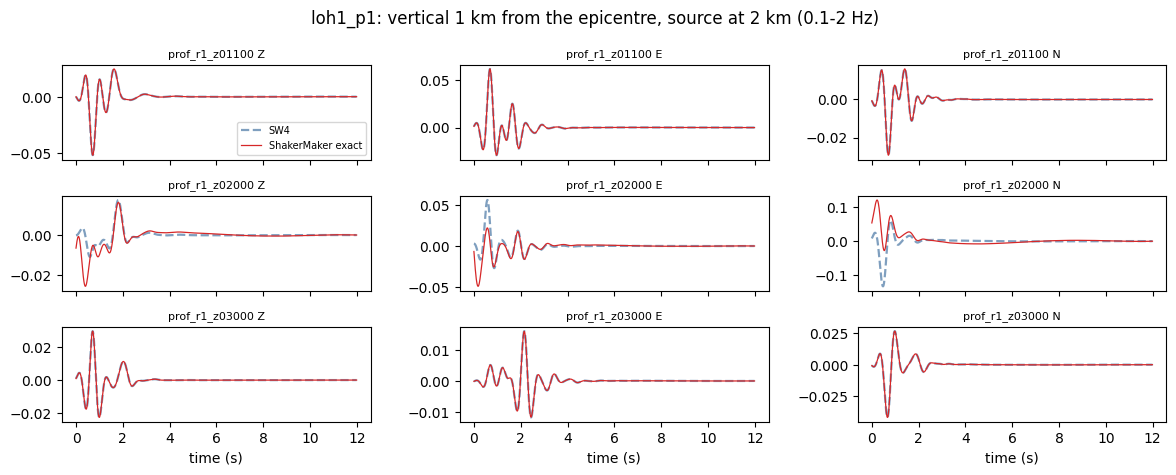

In [6]:
traces_figure("loh1_p1", ["prof_r1_z01100", "prof_r1_z02000", "prof_r1_z03000"],
              "loh1_p1: vertical 1 km from the epicentre, source at 2 km (0.1-2 Hz)", "source_depth_receiver.png")

**2. Shallow source under the soft layer, 1-2 Hz.** In `layered_p2` (source at 0.5 km under the 200 m layer at
0.75 km/s) the agreement is excellent below 1 Hz; in 1-2 Hz the best-lag shift grows with distance. It matches the
effective interface of SW4, half a cell deeper than the nominal one, which surface waves trapped in the thin layer
amplify.

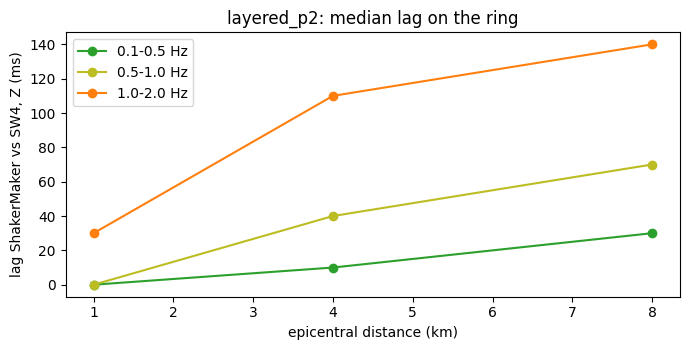

In [7]:
def best_lag(a, b, maxlag=0.15):
    nl = int(maxlag / dt)
    lags = np.arange(-nl, nl + 1)
    cc = [np.corrcoef(a[max(k, 0):len(a) + min(k, 0)], b[max(-k, 0):len(b) - max(k, 0)])[0, 1] for k in lags]
    return lags[int(np.argmax(cc))] * dt


n4, u4 = sw4["layered_p2"]
u = sm[("layered_p2", "exact")]
fig, ax = plt.subplots(figsize=(7, 3.6))
for (f1, f2), col in (((0.1, 0.5), "tab:green"), ((0.5, 1.0), "tab:olive"), ((1.0, 2.0), "tab:orange")):
    out = []
    for r in (1, 4, 8):
        lags = [best_lag(band(u4[n4.index(f"ring_r{r}_a{a:03d}")][0], f1, f2), band(u[n4.index(f"ring_r{r}_a{a:03d}")][0], f1, f2))
                for a in range(0, 360, 30)]
        out.append(1000 * np.median(lags))
    ax.plot([1, 4, 8], out, "o-", color=col, label=f"{f1}-{f2} Hz")
ax.set_xlabel("epicentral distance (km)"); ax.set_ylabel("lag ShakerMaker vs SW4, Z (ms)"); ax.legend()
ax.set_title("layered_p2: median lag on the ring"); fig.tight_layout(); fig.savefig("layered_p2_lag.png", dpi=130)

## Conclusions

- ShakerMaker (`exact`) matches SW4 in shape and in absolute amplitude in LOH.1 for the three sources, at the surface
  and at depth, in the three bands (median correlation 0.9998-1.0000, peaks within 1 %), and in the layered crust
  for the deep source (median correlation 0.997-1.000).
- In the layered crust the shallow source and the fault (sources in the 800 m layer under the 200 m soft layer) agree
  below 1 Hz; above it ShakerMaker lags SW4 by up to 70 ms (0.5-1 Hz) and 140 ms (1-2 Hz) at 8 km, growing with
  distance (finding 2), attributed to the effective interface of SW4, half a cell deeper than the nominal one.
- `run_inter(scheme='tensor')` stays within about 1-2 % of the exact traces and within 1-3 % on the DRM layer
  difference; `nearest` copies the Green's function of the slot and gets that difference wrong by 40-80 %.
- Open: receivers at the depth of a source (finding 1).

Regenerate the reference: `make_sw4_inputs.py --write`, SW4 on `sw4/*.in` (8-60 min per case on one node), then
`run_shakermaker.py <case> <engine>` with MPI.